# LEAR - backtest

Forecasts are saved under `results/lear/test/full/<model>.csv`.

Backtest of LEAR on the test set, every day of it (364 days). The model is the same as in `03_model_selection/01_LEAR.ipynb`: every day it is recalibrated on the last `calibration_window` days and forecasts all 24 hourly prices of the next day, with one LASSO regression per hour. Two windows are run: 728 and 1092 days, that is 2 and 3 years of 364 days.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

from src.config import EPF_EXOG
from src.utils.epf import evaluate_lear, forecast_path
from src.utils.evaluation import compare_models, load_forecasts
from src.utils.file_io import load_final_dataset

/opt/homebrew/Caskroom/miniforge/base/envs/epf-lear-dnn/lib/python3.10/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
dataset_full = load_final_dataset("epf", "pl", "full")
dataset_test = load_final_dataset("epf", "pl", "test")
prices = dataset_full["PL_price"]

configs = [
    {"model": "LEAR_728", "calibration_window": 728, "exog": EPF_EXOG},
    {"model": "LEAR_1092", "calibration_window": 1092, "exog": EPF_EXOG},
]

test_start = dataset_test.index.min()
test_end = dataset_test.index.max()

## 1. Backtest

Each window is run once over every day of the test set. The forecasts are saved to `results/lear/test/full/<model>.csv`, and the comparison below reads the files instead of recomputing them.

In [ ]:
for config in configs:
    evaluate_lear(
        dataset=dataset_full,
        calibration_window=config["calibration_window"],
        exog=config["exog"],
        forecast_start=test_start,
        forecast_end=test_end,
        path=forecast_path(config["model"], split="test", run="full"),
    )

## 2. Backtest comparison

Forecasts are scored against `PL_price`. MAE and RMSE are in EUR/MWh. rMAE is the MAE divided by the MAE of a naive forecast that repeats the price from the same hour one week earlier, so a value below 1 beats that naive forecast. Lower is better for all three.

In [3]:
models = [config["model"] for config in configs]
forecasts = load_forecasts(
    [forecast_path(model, split="test", run="full") for model in models]
)

compare_models(forecasts, prices, metrics=["rMAE", "MAE", "RMSE", "sMAPE"])

,rMAE,MAE,RMSE,sMAPE
model,,,,
LEAR_728,0.603856,22.395072,36.400590,0.282485
LEAR_1092,0.598969,22.213831,35.660759,0.280358


## 3. Error analysis

The error of an hour is the absolute difference from `PL_price`, and each point is the mean of those differences. The two calibration windows, 728 and 1092 days, are drawn together.

In [4]:
from src.utils.plots import plot_heatmap, plot_lines, plot_weekday

MODELS = ["728", "1092"]
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

aligned = prices.reindex(forecasts.index)
err = forecasts.rsub(aligned, axis=0).abs()
err = err.rename(columns={"LEAR_728": "728", "LEAR_1092": "1092"})[MODELS]
idx = err.index
by_hour = err.groupby(idx.hour).mean()
by_dow = err.groupby(idx.dayofweek).mean()
by_dow.index = DOW
by_month = err.groupby(idx.to_period("M")).mean()
by_month.index = by_month.index.astype(str)

### Hour

Each point is the mean absolute error of that hour over the test year.

In [5]:
by_hour.round(2)

,728,1092
0,8.79,9.15
1,9.84,9.97
2,10.81,11.07
3,11.13,11.41
4,11.44,11.65
5,11.74,11.65
6,16.29,15.75
7,20.71,20.66
8,22.98,23.41
9,24.78,25.43


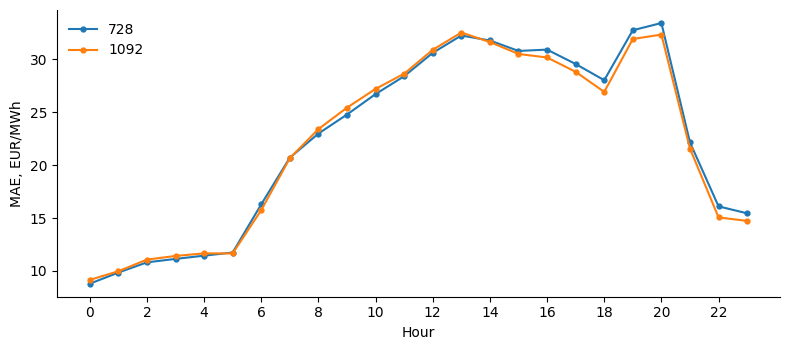

In [6]:
plot_lines(by_hour, xlabel="Hour", xticks=range(0, 24, 2))

### Weekday

In [7]:
by_dow.round(2)

,728,1092
Mon,26.62,25.76
Tue,24.88,24.60
Wed,22.14,21.66
Thu,22.73,22.63
Fri,21.08,21.01
Sat,20.05,20.05
Sun,19.26,19.79


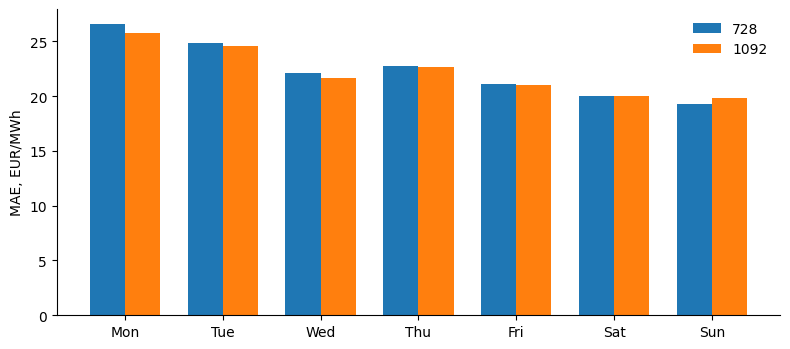

In [8]:
plot_weekday(by_dow)

### Month

Months run in chronological order. October 2025 starts on the 20th, and October 2026 ends on the 18th. The other months are complete.

In [9]:
by_month.round(2)

,728,1092
2025-10,22.56,21.88
2025-11,20.80,20.27
2025-12,13.93,14.09
2026-01,29.79,29.64
2026-02,12.17,11.86
2026-03,20.36,21.22
2026-04,23.50,23.96
2026-05,19.73,19.77
2026-06,23.23,23.16
2026-07,20.71,21.47


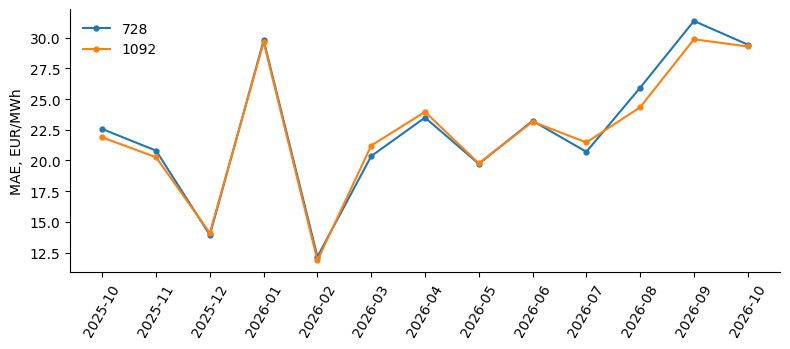

In [10]:
plot_lines(by_month, rotation=60)

### Hour by weekday

The two panels share one color scale.

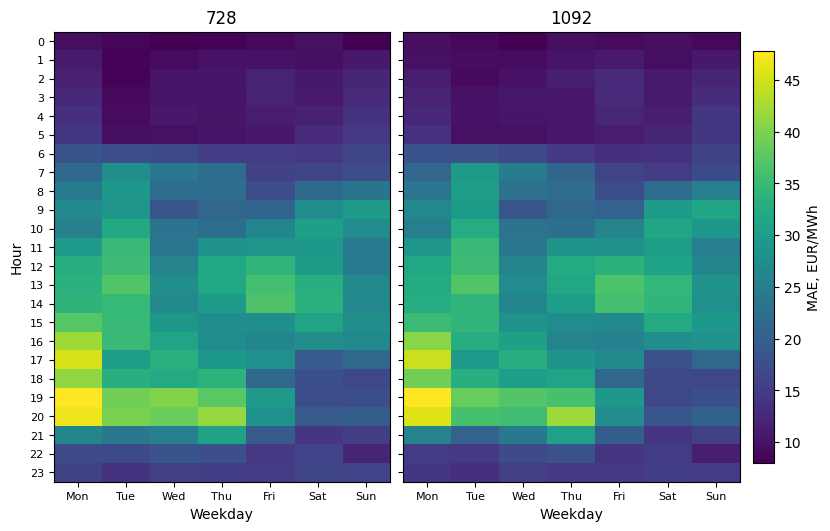

In [11]:
mats = []
for model in MODELS:
    mat = err[model].groupby([idx.hour, idx.dayofweek]).mean().unstack()
    mat.columns = DOW
    mats.append(mat)
plot_heatmap(mats, "Hour", "Weekday", MODELS)

### Weekday by month

The two panels share one color scale. The two Octobers are partial, and they are not the same month.

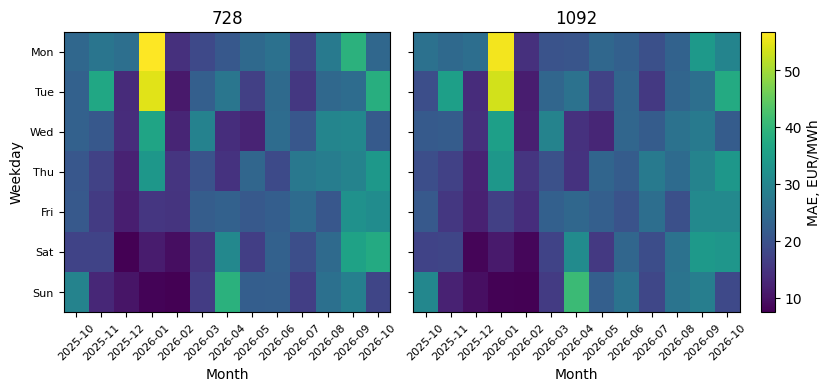

In [12]:
mats = []
for model in MODELS:
    mat = err[model].groupby([idx.dayofweek, idx.to_period("M")]).mean().unstack()
    mat.index = DOW
    mat.columns = mat.columns.astype(str)
    mats.append(mat)
plot_heatmap(mats, "Weekday", "Month", MODELS)